In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\ACC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [2]:
data = pd.read_csv('used_cars_dataset.csv')

## EDA

In [3]:
data.head()

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           3000 non-null   object 
 1   brand                3000 non-null   object 
 2   model                3000 non-null   object 
 3   year                 3000 non-null   int64  
 4   mileage_km           2822 non-null   float64
 5   transmission         2941 non-null   object 
 6   fuel_type            2940 non-null   object 
 7   engine_cc            2879 non-null   float64
 8   body_type            3000 non-null   object 
 9   color                2851 non-null   object 
 10  city                 2941 non-null   object 
 11  seller_type          2942 non-null   object 
 12  accident_history     3000 non-null   object 
 13  previous_owners      2881 non-null   float64
 14  condition_rating     2851 non-null   object 
 15  photos_count         2907 non-null   f

In [5]:
data.isnull().sum()

listing_id               0
brand                    0
model                    0
year                     0
mileage_km             178
transmission            59
fuel_type               60
engine_cc              121
body_type                0
color                  149
city                    59
seller_type             58
accident_history         0
previous_owners        119
condition_rating       149
photos_count            93
price_egp                0
sold_within_30_days      0
dtype: int64

In [6]:
data.describe()

,year,mileage_km,engine_cc,previous_owners,photos_count,price_egp
count,3000.000000,2.822000e+03,2879.000000,2881.000000,2907.000000,3.000000e+03
mean,2018.174333,1.093424e+05,1654.430358,1.887886,10.543172,7.555841e+05
std,37.275449,2.707599e+05,526.287599,1.008779,8.393483,2.043534e+06
min,0.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000e+00
25%,2017.000000,5.020000e+04,1500.000000,1.000000,8.000000,3.300000e+05
50%,2020.000000,8.570000e+04,1600.000000,2.000000,10.000000,5.525000e+05
75%,2022.000000,1.339250e+05,1600.000000,2.000000,13.000000,9.400000e+05
max,2050.000000,9.999999e+06,20000.000000,6.000000,300.000000,1.000000e+08


## فيه قيم مش منطقية (outliers)!!
1. year 0 .. 2050!!
2. mileage_km 0 .. 999999999999999999!!!
3. etc...

In [7]:
data.duplicated().sum()

np.int64(40)

## Cleaning

1. remove the listing_id column
2. working on (transmition - seller_type - accident_history) columns
3. remove duplicates
4. Replace Nan Values (Imputing)

In [8]:
data.columns

Index(['listing_id', 'brand', 'model', 'year', 'mileage_km', 'transmission',
       'fuel_type', 'engine_cc', 'body_type', 'color', 'city', 'seller_type',
       'accident_history', 'previous_owners', 'condition_rating',
       'photos_count', 'price_egp', 'sold_within_30_days'],
      dtype='object')

In [9]:
print("\nUnique Transmissions:", data['transmission'].unique())
print("Unique Accident History:", data['accident_history'].unique())
print("Sample Brands:", data['brand'].unique()[:15])


Unique Transmissions: ['Automatic' 'Manual' 'Auto' nan 'MT']
Unique Accident History: ['No' 'Yes' 'N' 'Y']
Sample Brands: ['MG' 'Kia' 'Skoda' 'Fiat' 'Mitsubishi' 'Toyota' 'Hyundai' 'Nissan'
 'Chevrolet' 'Mercedes' 'TOYOTA' 'BMW' 'Renault' 'KIA' 'Mercedes-Benz']


In [10]:
data['transmission'] = data['transmission'].replace({'Auto' : 'Automatic', 'MT' : 'Manual'})

data['seller_type'] = data['seller_type'].str.capitalize()

data['accident_history'] = data['accident_history'].replace({'Y':'Yes', 'N':'No'})

In [11]:
print("\nUnique Transmissions:", data['transmission'].unique())
print("Unique Accident History:", data['accident_history'].unique())
print("Sample Brands:", data['brand'].unique()[:15])


Unique Transmissions: ['Automatic' 'Manual' nan]
Unique Accident History: ['No' 'Yes']
Sample Brands: ['MG' 'Kia' 'Skoda' 'Fiat' 'Mitsubishi' 'Toyota' 'Hyundai' 'Nissan'
 'Chevrolet' 'Mercedes' 'TOYOTA' 'BMW' 'Renault' 'KIA' 'Mercedes-Benz']


In [12]:
# Remove the (listing_id) column

data.drop('listing_id', axis=1, inplace = True)

data.head()

,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


In [13]:
# Remove duplicates

data.drop_duplicates(inplace = True)
data.reset_index(drop = True, inplace = True)

print(data.duplicated().sum())

0


In [14]:
# إزالة المسافات الزائدة من جميع الأعمدة النصية

for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].astype(str).str.strip()
    # إرجاع القيم الفارغة التي تحولت لنص 'nan' إلى np.nan الأصلي
    data.loc[data[col].isin(['nan', 'None', '']), col] = np.nan

In [15]:
# Normalization

data['brand'] = data['brand'].str.title().replace({
    'Bmw': 'BMW',
    'Mg': 'MG',
    'Mercedes': 'Mercedes-Benz',
    'Mercedes-Benz': 'Mercedes-Benz'
})
data['city'] = data['city'].str.title()
data['seller_type'] = data['seller_type'].str.title()

In [16]:
# Outliers Filtering

data = data[
    (data['year'] >= 1990) & (data['year'] <= 2025) &
    ((data['mileage_km'].isna()) | ((data['mileage_km'] > 0) & (data['mileage_km'] <= 400000))) &
    ((data['engine_cc'].isna()) | ((data['engine_cc'] >= 800) & (data['engine_cc'] <= 5000))) &
    ((data['photos_count'].isna()) | (data['photos_count'] <= 40)) &
    (data['price_egp'] >= 50000) & (data['price_egp'] <= 6000000)
]

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2910 entries, 0 to 2959
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                2910 non-null   object 
 1   model                2910 non-null   object 
 2   year                 2910 non-null   int64  
 3   mileage_km           2740 non-null   float64
 4   transmission         2851 non-null   object 
 5   fuel_type            2851 non-null   object 
 6   engine_cc            2791 non-null   float64
 7   body_type            2910 non-null   object 
 8   color                2764 non-null   object 
 9   city                 2854 non-null   object 
 10  seller_type          2855 non-null   object 
 11  accident_history     2910 non-null   object 
 12  previous_owners      2793 non-null   float64
 13  condition_rating     2762 non-null   object 
 14  photos_count         2823 non-null   float64
 15  price_egp            2910 non-null   int64 

In [18]:
# Replace Nan Values

data.isnull().sum().sort_values(ascending = False)

mileage_km             170
condition_rating       148
color                  146
engine_cc              119
previous_owners        117
photos_count            87
fuel_type               59
transmission            59
city                    56
seller_type             55
brand                    0
year                     0
model                    0
body_type                0
accident_history         0
price_egp                0
sold_within_30_days      0
dtype: int64

In [19]:
# Imputation

# تعويض سعة المحرك والفتيس ونوع الوقود حسب القيمة الأكثر تكراراً لنفس موديل السيارة
for col in ['engine_cc', 'transmission', 'fuel_type']:
    data[col] = data.groupby('model')[col].transform(lambda x: x.fillna(x.mode()[0]))

# تعويض عداد الكيلومترات المفقود بوسيط الكيلومترات للسيارات من نفس سنة الصنع
data['mileage_km'] = data.groupby('year')['mileage_km'].transform(lambda x: x.fillna(x.median()))
data['mileage_km'] = data['mileage_km'].fillna(data['mileage_km'].median())

In [20]:
# ba2y el categorical columns hn3wad bl mode
cat_cols =['color','city','seller_type','accident_history','condition_rating']
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# wl numerical bl median
num_cols = ['photos_count','previous_owners']
for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

In [21]:
# Feature Engineering
data['car_age'] = 2026 - data['year'] 
data['km_per_year'] = data['mileage_km'] / data['car_age'].replace(0, 1)

print(f"Remaining Rows After Cleaning: {len(data)}") 
print(f"Total Missing Values: {data.isnull().sum().sum()}")

Remaining Rows After Cleaning: 2910
Total Missing Values: 0


## Visualizations

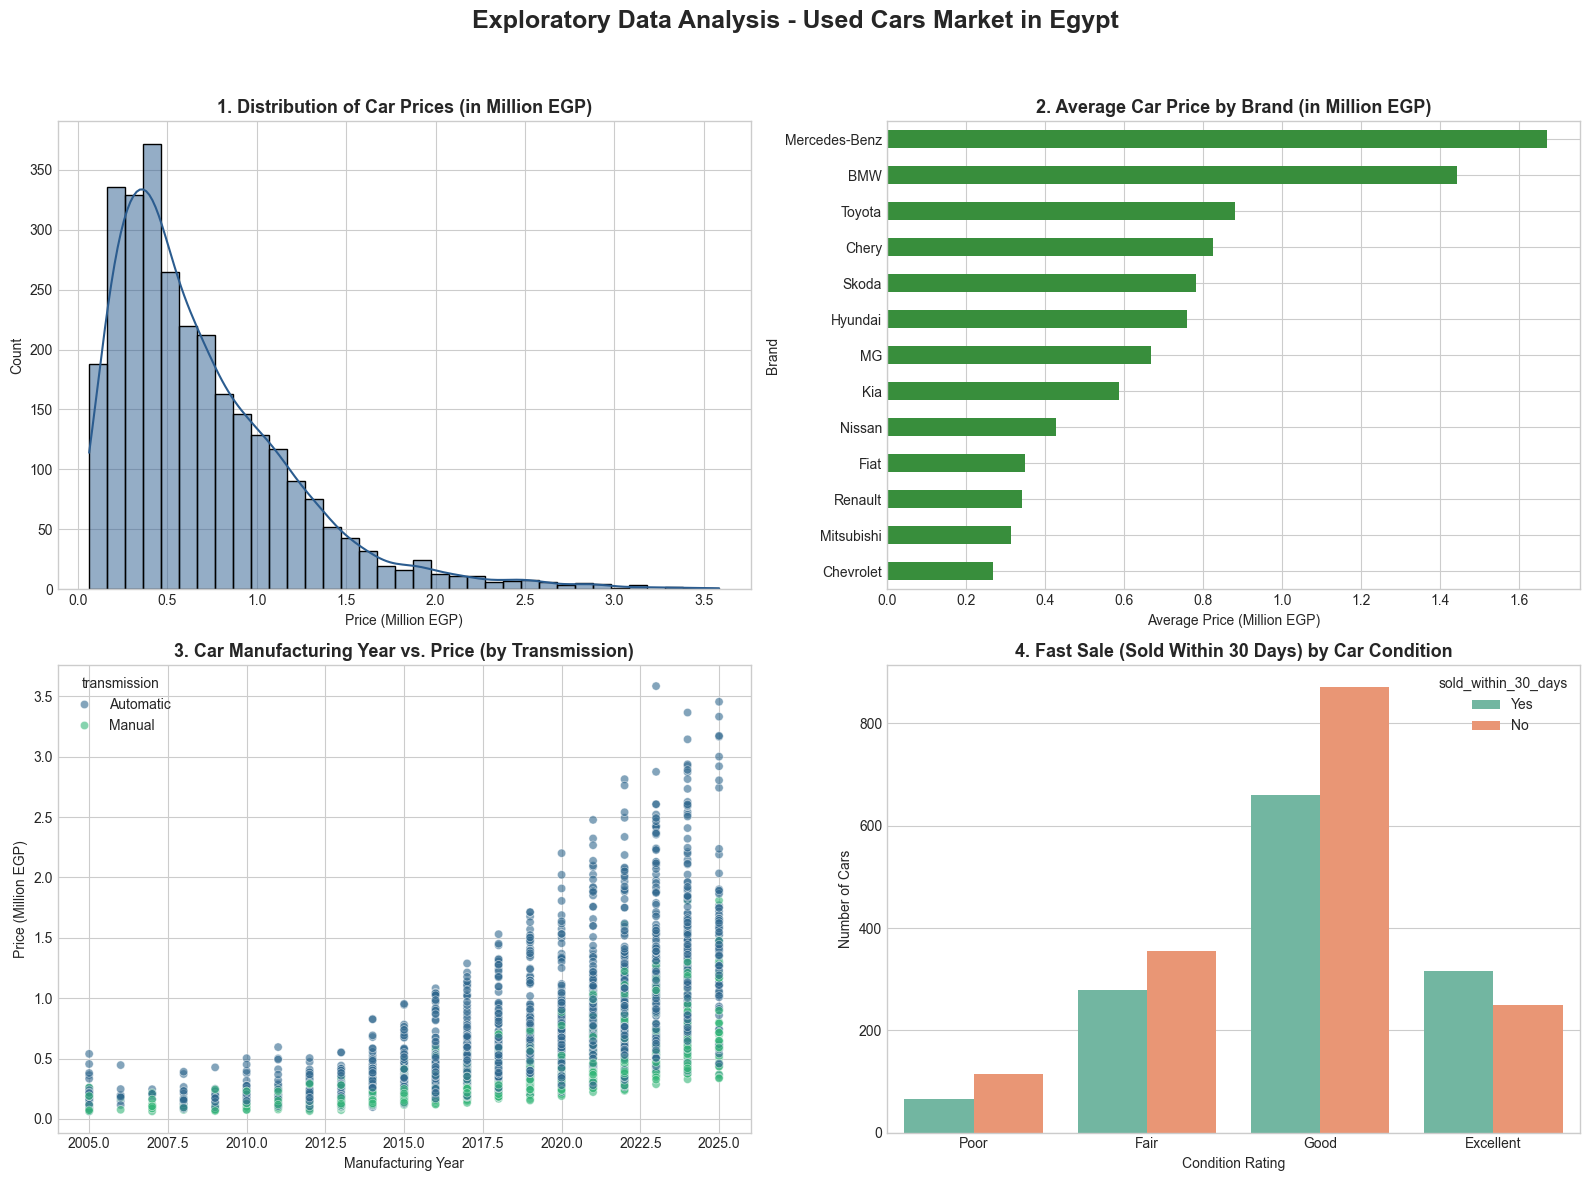

In [22]:
# ضبط شكل وتصميم الرسوم البيانية
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Exploratory Data Analysis - Used Cars Market in Egypt', fontsize=18, fontweight='bold', y=0.98)

# 1. رسم توزيع أسعار السيارات بالمليون جنيه (Histogram + KDE)
sns.histplot(data['price_egp'] / 1e6, bins=35, kde=True, color='#2b5c8f', ax=axes[0, 0])
axes[0, 0].set_title('1. Distribution of Car Prices (in Million EGP)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Price (Million EGP)')
axes[0, 0].set_ylabel('Count')

# 2. رسم متوسط الأسعار حسب الماركة (Horizontal Bar Chart)
brand_price = data.groupby('brand')['price_egp'].mean().sort_values(ascending=True) / 1e6
brand_price.plot(kind='barh', color='#388e3c', ax=axes[0, 1])
axes[0, 1].set_title('2. Average Car Price by Brand (in Million EGP)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Average Price (Million EGP)')
axes[0, 1].set_ylabel('Brand')

# 3. علاقة سنة الصنع بالسعر مع التمييز بنوع الفتيس (Scatter Plot)
sns.scatterplot(data=data, x='year', y=data['price_egp']/1e6, hue='transmission', alpha=0.6, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_title('3. Car Manufacturing Year vs. Price (by Transmission)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Manufacturing Year')
axes[1, 0].set_ylabel('Price (Million EGP)')

# 4. علاقة حالة السيارة بسرعة البيع خلال 30 يوماً (Count Plot)
sns.countplot(data=data, x='condition_rating', hue='sold_within_30_days', order=['Poor', 'Fair', 'Good', 'Excellent'], palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('4. Fast Sale (Sold Within 30 Days) by Car Condition', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Condition Rating')
axes[1, 1].set_ylabel('Number of Cars')

# تنسيق المسافات وعرض الرسم
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Encoding

In [23]:
# One-Hot Encoding
X = data.drop('price_egp', axis=1)
y = data['price_egp']

X = pd.get_dummies(X, drop_first=True)
print("Shape of X after encoding:", X.shape)

Shape of X after encoding: (2910, 56)


## Train Test Split

In [24]:
# التقسيم إلى تدريب واختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# تحجيم البيانات (مهم لموديلات مثل SVR, KNN, Linear Models)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Preprocessing

In [25]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

In [26]:
num_cols = ['year', 'car_age', 'mileage_km', 'km_per_year', 'engine_cc', 'previous_owners', 'photos_count']
ord_cols = ['condition_rating']
cat_cols = ['brand', 'model', 'transmission', 'fuel_type', 'body_type', 'color', 'city', 'seller_type', 'accident_history']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('ord', OrdinalEncoder(categories=[['Poor', 'Fair', 'Good', 'Excellent']]), ord_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

## Model Training

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "K-Neighbors": KNeighborsRegressor(),
    "SVR": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Bagging": BaggingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1)
}

results = []

for name, model in tqdm(models.items(), desc="Training Models"):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
display(results_df)

Training Models:  13%|█▎        | 2/15 [00:00<00:01, 10.36it/s]c:\Users\ACC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.387e+12, tolerance: 6.293e+10
  model = cd_fast.enet_coordinate_descent(
Training Models: 100%|██████████| 15/15 [00:30<00:00,  2.00s/it]


,Model,MAE,RMSE,R2 Score
11,Hist Gradient Boosting,67692.650939,106914.302777,0.944377
14,LightGBM,69688.106349,109189.193859,0.941985
13,CatBoost,69104.791483,111205.705608,0.939822
12,XGBoost,81309.226562,127202.733052,0.921264
6,Random Forest,89082.094215,136964.731601,0.908715
7,Extra Trees,89154.475945,140095.507644,0.904494
8,Bagging,97070.432417,148283.212070,0.893004
10,Gradient Boosting,94961.821054,150304.218370,0.890068
5,Decision Tree,118273.195876,189114.085824,0.825968
1,Ridge,144753.583735,205088.331728,0.795326


# Votting Regression

In [28]:
from sklearn.ensemble import VotingRegressor, StackingRegressor

# اختيار أفضل موديلات أساسية للدمج
estimators = [
    ('rf', RandomForestRegressor(random_state=42)),
    ('xgb', XGBRegressor(random_state=42)),
    ('cat', CatBoostRegressor(verbose=0, random_state=42))
]

# 1. Voting Regressor
voting_model = VotingRegressor(estimators=estimators)
voting_model.fit(X_train_scaled, y_train)
v_pred = voting_model.predict(X_test_scaled)
print("Voting R2 Score:", r2_score(y_test, v_pred))

# 2. Stacking Regressor (باستخدام LinearRegression كميتا-موديل نهائي)
stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=LinearRegression()
)
stacking_model.fit(X_train_scaled, y_train)
s_pred = stacking_model.predict(X_test_scaled)
print("Stacking R2 Score:", r2_score(y_test, s_pred))

Voting R2 Score: 0.9370556804243091
Stacking R2 Score: 0.9396281288747884
